#Exploratory Data Analysis

This dataset is composed by 5000 CVs...

In [2]:
!pip3 install pandas

In [34]:
import json
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns

In [4]:
from pathlib import Path
import json
import pandas as pd

def readfiles(raw_data_path):
    raw_path = Path(raw_data_path)
    texts = []
    annotations_ = []

    for json_file in raw_path.rglob("*.json"):
        with open(json_file, 'r', encoding='utf-8', errors='replace') as f:
            data = json.load(f)
            
            text = data.get("text", "")
            
            # Clean lone surrogates that crash PyArrow/Pandas
            if isinstance(text, str):
                text = text.encode("utf-8", "surrogatepass").decode("utf-8", "ignore")
            
            annotations = data.get("annotations", [])

            texts.append(text)
            annotations_.append(annotations)
            
    df_skills = pd.DataFrame({"text": texts, "annotations": annotations_})
    return df_skills

In [5]:
df_skills = readfiles("data/raw")

In [6]:
df_skills.head()

,text,annotations
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL..."
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ..."
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK..."
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI..."
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI..."


In [7]:
df_skills["annotations"][0:2].tolist()

[[[657, 665, 'SKILL: Building'],
  [822, 828, 'SKILL: python'],
  [811, 815, 'SKILL: java'],
  [781, 790, 'SKILL: Knowledge'],
  [877, 887, 'SKILL: Processing'],
  [194, 205, 'SKILL: performance'],
  [442, 452, 'SKILL: Technology'],
  [1007, 1014, 'SKILL: PySpark'],
  [30, 44, 'SKILL: Data Scientist'],
  [153, 162, 'SKILL: Detection'],
  [329, 345, 'SKILL: computer science'],
  [102, 108, 'SKILL: Images'],
  [889, 902, 'SKILL: Deep Learning'],
  [942, 954, 'SKILL: data science'],
  [1031, 1037, 'SKILL: skills'],
  [1147, 1155, 'SKILL: Projects'],
  [734, 737, 'SKILL: CAN'],
  [575, 590, 'SKILL: Market Research'],
  [956, 969, 'SKILL: Data Analysis'],
  [904, 919, 'SKILL: Computer Vision'],
  [802, 809, 'SKILL: Process'],
  [817, 818, 'SKILL: C'],
  [164, 167, 'SKILL: OCR'],
  [604, 612, 'SKILL: Analysis'],
  [838, 846, 'SKILL: Learning'],
  [971, 988, 'SKILL: Software Engineer'],
  [338, 345, 'SKILL: Science'],
  [267, 278, 'SKILL: Probability'],
  [772, 780, 'SKILL: Exchange'],
  [379

In [8]:
def extract_skills(annotation_list):
    # This list comprehension pulls the string from index 2 of each sub-list
    return [item[2] for item in annotation_list]

# Create the new column
df_skills['skills_list'] = df_skills['annotations'].apply(extract_skills)

# Optional: If you want a single string separated by commas instead of a list:
# df_skills['skills_string'] = df_skills['skills_list'].apply(lambda x: ", ".join(x))

In [9]:
df_skills.head()


,text,annotations,skills_list
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[SKILL: Building, SKILL: python, SKILL: java, ..."
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[SKILL: scikit, SKILL: python, SKILL: Scikit l..."
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK..."
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[SKILL: WINDOWS XP, SKILL: Problem solving, SK..."
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,..."


In [10]:
df_skills["skills_list"][0]

['SKILL: Building',
 'SKILL: python',
 'SKILL: java',
 'SKILL: Knowledge',
 'SKILL: Processing',
 'SKILL: performance',
 'SKILL: Technology',
 'SKILL: PySpark',
 'SKILL: Data Scientist',
 'SKILL: Detection',
 'SKILL: computer science',
 'SKILL: Images',
 'SKILL: Deep Learning',
 'SKILL: data science',
 'SKILL: skills',
 'SKILL: Projects',
 'SKILL: CAN',
 'SKILL: Market Research',
 'SKILL: Data Analysis',
 'SKILL: Computer Vision',
 'SKILL: Process',
 'SKILL: C',
 'SKILL: OCR',
 'SKILL: Analysis',
 'SKILL: Learning',
 'SKILL: Software Engineer',
 'SKILL: Science',
 'SKILL: Probability',
 'SKILL: Exchange',
 'SKILL: M',
 'SKILL: vision',
 'SKILL: Communications',
 'SKILL: Language Processing',
 'SKILL: Team',
 'SKILL: Data',
 'SKILL: Natural Language Processing',
 'SKILL: Engineer',
 'SKILL: Object detection',
 'SKILL: Pattern',
 'SKILL: Computer Science Engineering',
 'SKILL: machine learning',
 'SKILL: Kubeflow',
 'SKILL: Research',
 'SKILL: Patterns',
 'SKILL: Premium',
 'SKILL: Probl

In [11]:
df_skills["num_annon"]=df_skills["skills_list"].apply(len)

<Axes: >

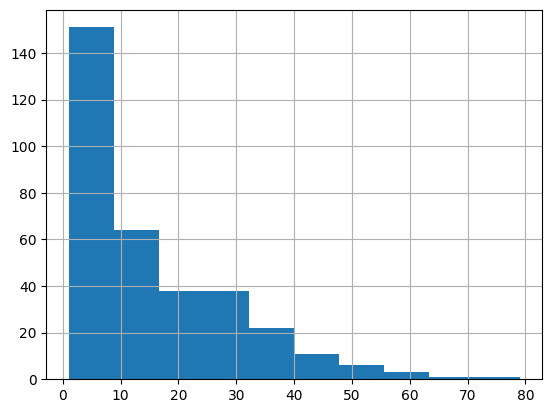

In [12]:
df_skills["num_annon"].value_counts().hist()

#Há uma tendência para os currículso terem, em média, 10 annotações.

#Verificar se são todas skills ou não

In [13]:
df_skills["skills_list"]

0       [SKILL: Building, SKILL: python, SKILL: java, ...
1       [SKILL: scikit, SKILL: python, SKILL: Scikit l...
2       [SKILL: reporting, SKILL: Business Studies, SK...
3       [SKILL: WINDOWS XP, SKILL: Problem solving, SK...
4       [SKILL: Test cases, SKILL: GMail, SKILL: java,...
                              ...                        
5024    [SKILL: Sensor, SKILL: Music, SKILL: Advertisi...
5025    [SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...
5026    [SKILL: Reports, SKILL: VMware, SKILL: Typing,...
5027    [SKILL: Inventory, SKILL: GMail, SKILL: Knowle...
5028    [SKILL: Debugging skills, SKILL: Ability, SKIL...
Name: skills_list, Length: 5029, dtype: object

In [14]:
["abc", "def", "ghi"] + ["jkl", "mno"]

['abc', 'def', 'ghi', 'jkl', 'mno']

In [15]:
unique_skills = df_skills["skills_list"].explode().unique().tolist()

In [16]:
len(unique_skills)

12696

In [17]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skills_list
SKILL: COM                       3874
SKILL: skills                    3805
SKILL: Work                      3679
SKILL: Personal                  3458
SKILL: Knowledge                 3417
                                 ... 
SKILL: Information Governance       1
SKILL: Emergency Rooms              1
SKILL: iHeart Radio                 1
SKILL: Big Bang                     1
SKILL: Debugging skills             1
Name: count, Length: 12695, dtype: int64


<Axes: xlabel='skills_list'>

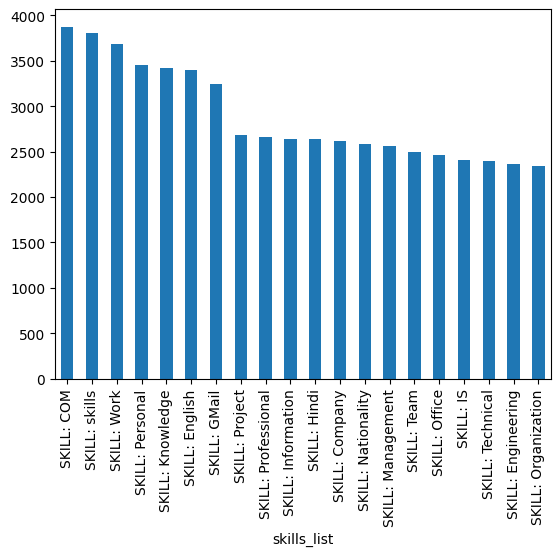

In [18]:
skill_counts.head(20).plot(kind='bar')

In [19]:
df_skills

,text,annotations,skills_list,num_annon
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[SKILL: Building, SKILL: python, SKILL: java, ...",70
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[SKILL: scikit, SKILL: python, SKILL: Scikit l...",32
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK...",52
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[SKILL: WINDOWS XP, SKILL: Problem solving, SK...",42
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,...",80
...,...,...,...,...
5024,"\t\n\t\n\t\n\t\n \nDestinee Handly, Manicurist...","[[1283, 1289, SKILL: Sensor], [1305, 1310, SKI...","[SKILL: Sensor, SKILL: Music, SKILL: Advertisi...",12
5025,"\t\n\t\n\t\n \nDevon Nuszer, Wardrobe Stylist...","[[207, 211, SKILL: ADAM], [755, 758, SKILL: CA...","[SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...",8
5026,RESUME\nName :Gaurav Dwivedi\nAge :27 Years\nD...,"[[2070, 2077, SKILL: Reports], [2399, 2405, SK...","[SKILL: Reports, SKILL: VMware, SKILL: Typing,...",72
5027,ResumeNitesh\nNITESH KUMAR\n Email id: niteshj...,"[[1876, 1885, SKILL: Inventory], [73, 78, SKIL...","[SKILL: Inventory, SKILL: GMail, SKILL: Knowle...",89


In [20]:
df_skills[df_skills["skills_list"].apply(lambda x: "SKILL: COM" in x)]

,text,annotations,skills_list,num_annon
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK...",52
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,...",80
6,"\t\n\t\n\t\n\t\n\t\n\t\nBarbara Farman, Hair,...","[[787, 793, SKILL: Hunter], [1618, 1624, SKILL...","[SKILL: Hunter, SKILL: Health, SKILL: ADAMS, S...",36
7,"\n2632 La Cienega Avenue Los Angeles, C...","[[847, 853, SKILL: Hunter], [2447, 2451, SKILL...","[SKILL: Hunter, SKILL: COLA, SKILL: Australia,...",23
8,"\n \n \n \nBethany Newell, Manicurist \nwww.c...","[[968, 980, SKILL: Self service], [1799, 1805,...","[SKILL: Self service, SKILL: Forbes, SKILL: co...",21
...,...,...,...,...
5023,"\n \n \n \nDenika Bedrossian , Makeup Artist...","[[105, 109, SKILL: ADAM], [3504, 3512, SKILL: ...","[SKILL: ADAM, SKILL: Big Bang, SKILL: CAN, SKI...",38
5024,"\t\n\t\n\t\n\t\n \nDestinee Handly, Manicurist...","[[1283, 1289, SKILL: Sensor], [1305, 1310, SKI...","[SKILL: Sensor, SKILL: Music, SKILL: Advertisi...",12
5025,"\t\n\t\n\t\n \nDevon Nuszer, Wardrobe Stylist...","[[207, 211, SKILL: ADAM], [755, 758, SKILL: CA...","[SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...",8
5027,ResumeNitesh\nNITESH KUMAR\n Email id: niteshj...,"[[1876, 1885, SKILL: Inventory], [73, 78, SKIL...","[SKILL: Inventory, SKILL: GMail, SKILL: Knowle...",89


In [21]:
x=df_skills[df_skills["skills_list"].apply(lambda x: "SKILL: COM" in x)]
[ano for ano in x["annotations"].iloc[0] if "SKILL: COM" in ano]


[[103, 106, 'SKILL: COM']]

In [22]:
df_skills["text"][2][95:120]

'y@yahoo.com\nSummary\nProfi'

In [23]:
#Remover Prefixo "Skill"

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda x: [item.split(': ')[-1] if ': ' in item else item for item in x]
)

In [24]:
df_skills.head()

,text,annotations,skills_list,num_annon
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[Building, python, java, Knowledge, Processing...",70
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[scikit, python, Scikit learn, TensorFlow, Dee...",32
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[reporting, Business Studies, Managing, Maths,...",52
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[WINDOWS XP, Problem solving, Knowledge, Arts,...",42
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[Test cases, GMail, java, Knowledge, ASP, Crit...",80


In [25]:
df_skills["skills_list"].explode().value_counts()

skills_list
COM                             3874
skills                          3805
Work                            3679
Personal                        3458
Knowledge                       3417
                                ... 
Research Programs                  1
Continuing Medical Education       1
Big Bang                           1
iHeart Radio                       1
Debugging skills                   1
Name: count, Length: 12693, dtype: int64

In [26]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

def clean_skills_text(skills_list):
    stop_words = set(stopwords.words('english'))
    cleaned_list = []
    for skill in skills_list:

        words = skill.split()
        filtered_words = [w for w in words if w.lower() not in stop_words]
        cleaned_skill = " ".join(filtered_words).strip()
        if cleaned_skill:
            cleaned_list.append(cleaned_skill)
            
    return cleaned_list

df_skills['skills_list'] = df_skills['skills_list'].apply(clean_skills_text)

df_skills['skills_list'] = df_skills['skills_list'].apply(lambda x: list(set(x)))

In [52]:
blacklist = {"COM", "Skills" , "personal","information", "knowledge", "process", "skills", "can", "work", "marital status", "nationality", "com", "languages", "board", "email", "qualification","activities"}

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: [s for s in lista if s.lower() not in blacklist]
)


skills_list
English              3399
GMail                3238
Project              2683
Professional         2661
Hindi                2636
                     ... 
Research Programs       1
Emergency Rooms         1
Big Bang                1
iHeart Radio            1
Debugging skills        1
Name: count, Length: 12618, dtype: int64


<Axes: xlabel='skills_list'>

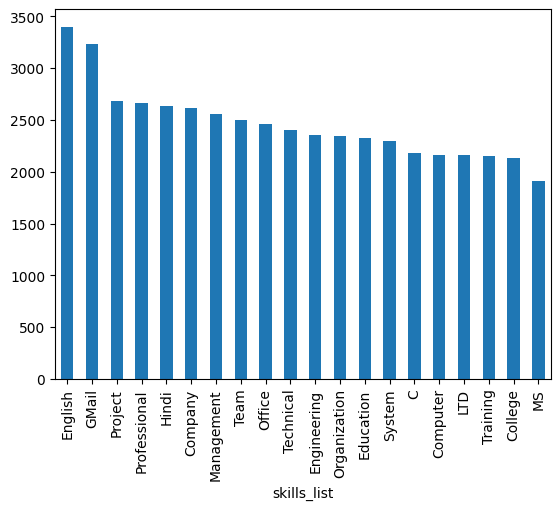

In [53]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skill_counts.head(20).plot(kind='bar')

#Removemos conectores(e.g "is") e outras skills que não eram relevantes"

Será que existem skills relacionadas?

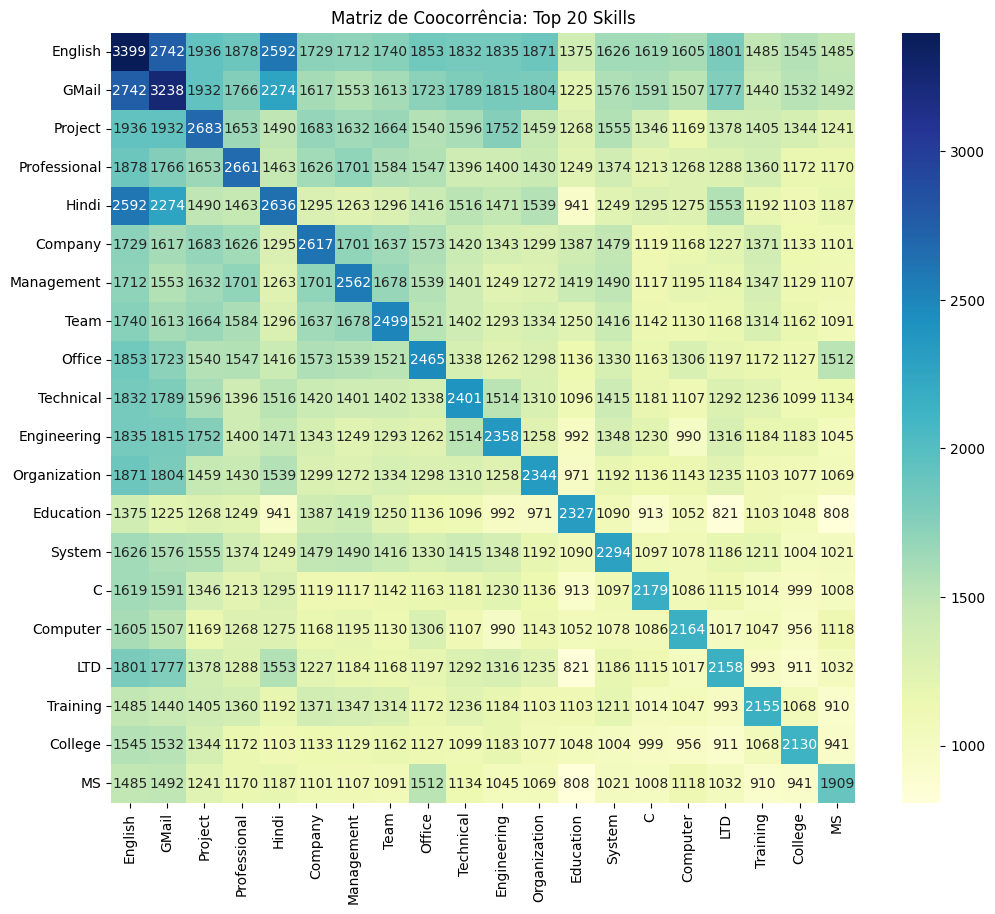

In [54]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
skills_encoded = pd.DataFrame(mlb.fit_transform(df_skills['skills_list']), 
                             columns=mlb.classes_, 
                             index=df_skills.index)

top_20_skills = df_skills['skills_list'].explode().value_counts().head(20).index
subset_encoded = skills_encoded[top_20_skills]

co_occurrence_matrix = subset_encoded.T.dot(subset_encoded)

plt.figure(figsize=(12, 10))
sns.heatmap(co_occurrence_matrix, annot=True, fmt="d", cmap="YlGnBu")
plt.title('Matriz de Coocorrência: Top 20 Skills')
plt.show()

E quais são as mais raras?

In [56]:
total_cvs = len(df_skills)
skill_counts = df_skills['skills_list'].explode().value_counts()

skills_stats = pd.DataFrame({
    'contagem': skill_counts,
    'percentagem': (skill_counts / total_cvs) * 100
})

limite_raridade = 1.0 
skills_raras = skills_stats[skills_stats['percentagem'] < limite_raridade]

print(f"Total de skills únicas: {len(skill_counts)}")
print(f"Total de skills raras (<{limite_raridade}%): {len(skills_raras)}")
print("\nExemplos de Skills Raras:")
print(skills_raras.tail(30))

Total de skills únicas: 12618
Total de skills raras (<1.0%): 11134

Exemplos de Skills Raras:
                              contagem  percentagem
skills_list                                        
Credit Review                        1     0.019885
Solvency                             1     0.019885
Quantitative modeling                1     0.019885
Legal Assistance                     1     0.019885
Law Degree                           1     0.019885
Correspondence preparation           1     0.019885
Client focus                         1     0.019885
bain                                 1     0.019885
OID                                  1     0.019885
Independent Decision Making          1     0.019885
Advanced research                    1     0.019885
Language Fluency                     1     0.019885
Medical imaging                      1     0.019885
Pharmacovigilance                    1     0.019885
Continuing Medical Education         1     0.019885
Medical management    

Usar mais comuns ou raras?